# Dashboard IoT Annuel 2019 — PEAKSOFT Cyber-Guardian
## Visualisation interactive des 3 capteurs (Weather, Fridge, Thermostat) + ML Isolation Forest

---
**Donnees** : 105 120 points (5 min) — 365 jours — 3 capteurs — 9 types d'attaque

**Notebook interactif** : selectionnez un capteur et une periode avec les widgets ci-dessous

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from ipywidgets import interact, widgets, Layout
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

sns.set_theme(style='darkgrid')
plt.rcParams.update({'figure.facecolor':'#0E1117', 'axes.facecolor':'#1A1D27',
    'axes.edgecolor':'#2E3440', 'axes.labelcolor':'#D8DEE9', 'text.color':'#D8DEE9',
    'xtick.color':'#81A1C1', 'ytick.color':'#81A1C1', 'grid.color':'#2E3440',
    'grid.alpha':0.3, 'font.size':11, 'axes.titlesize':14})

BASE = r'C:\peaksoft-security-platform-main\peaksoft-security-platform-main'
df = pd.read_csv(f'{BASE}/Data/Generated/generated_yearly_merged.csv')
df['datetime'] = pd.to_datetime(df['datetime'])
df['month'] = df['datetime'].dt.month; df['hour'] = df['datetime'].dt.hour
df['doy'] = df['datetime'].dt.dayofyear
print(f'Charge : {len(df):,} lignes | {df["datetime"].min().date()} a {df["datetime"].max().date()}')
print(f'Normal: {(df["label"]==0).sum():,} | Attaques: {(df["label"]==1).sum():,}')

Charge : 105,120 lignes | 2019-01-01 a 2019-12-31
Normal: 12,960 | Attaques: 92,160


---
## 1. Vue generale — Selectionnez un capteur

In [2]:
SENSOR_MAP = {
    'Weather (exterieur)': ('temperature', '#5E81AC', '°C'),
    'Fridge (frigo)': ('fridge_temperature', '#A3BE8C', '°C'),
    'Thermostat (interieur)': ('current_temperature', '#BF616A', '°C'),
}

def plot_sensor(sensor_name, start_doy=1, end_doy=365, show_attacks=True):
    col, color, unit = SENSOR_MAP[sensor_name]
    mask = (df['doy'] >= start_doy) & (df['doy'] <= end_doy)
    sdf = df[mask].copy()
    
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 8), gridspec_kw={'height_ratios': [3, 1]})
    
    # Timeline
    daily = sdf.groupby('doy')[col].agg(['mean','min','max'])
    ax1.fill_between(daily.index, daily['min'], daily['max'], alpha=0.12, color=color)
    ax1.plot(daily.index, daily['mean'], color=color, lw=1.5)
    if show_attacks:
        atk_daily = sdf[sdf['label']==1].groupby('doy')[col].mean()
        ax1.scatter(atk_daily.index, atk_daily, color='#E74C3C', s=15,
                   edgecolors='white', linewidth=0.3, alpha=0.6, zorder=5)
    ax1.set_ylabel(f'Temperature ({unit})')
    ax1.set_title(f'{sensor_name}', color=color, fontweight='bold', loc='left')
    ax1.set_xlim(start_doy, end_doy)
    
    # Histogram
    bins = 80
    ax2.hist(sdf[sdf['label']==0][col], bins=bins, alpha=0.5, color='#4CAF50',
             label='Normal', density=True)
    if show_attacks:
        ax2.hist(sdf[sdf['label']==1][col], bins=bins, alpha=0.5, color='#E74C3C',
                 label='Attaque', density=True)
    ax2.set_xlabel(f'Temperature ({unit})'); ax2.set_ylabel('Densite')
    ax2.legend(fontsize=9)
    
    fig.tight_layout(); plt.show()

interact(plot_sensor,
    sensor_name=widgets.Dropdown(options=list(SENSOR_MAP.keys()),
                                 value='Weather (exterieur)',
                                 description='Capteur :',
                                 style={'description_width':'initial'}),
    start_doy=widgets.IntSlider(min=1, max=365, value=1, description='Jour debut'),
    end_doy=widgets.IntSlider(min=1, max=365, value=365, description='Jour fin'),
    show_attacks=widgets.Checkbox(value=True, description='Afficher attaques'))

interactive(children=(Dropdown(description='Capteur :', options=('Weather (exterieur)', 'Fridge (frigo)', 'The…

<function __main__.plot_sensor(sensor_name, start_doy=1, end_doy=365, show_attacks=True)>

---
## 2. Comparaison des 3 capteurs

In [3]:
def compare_sensors(month_filter, show_attacks):
    if month_filter == 'Tous':
        sdf = df
    else:
        m = int(month_filter.split('-')[0])
        sdf = df[df['month'] == m]
    
    fig, axes = plt.subplots(3, 1, figsize=(16, 10), sharex=True)
    cols = [('temperature', '#5E81AC', 'Weather'),
            ('fridge_temperature', '#A3BE8C', 'Fridge'),
            ('current_temperature', '#BF616A', 'Thermostat')]
    
    for ax, (col, color, name) in zip(axes, cols):
        daily = sdf.groupby('doy')[col].agg(['mean','min','max'])
        ax.fill_between(daily.index, daily['min'], daily['max'], alpha=0.1, color=color)
        ax.plot(daily.index, daily['mean'], color=color, lw=1.5)
        if show_attacks:
            atk_d = sdf[sdf['label']==1].groupby('doy')[col].mean()
            ax.scatter(atk_d.index, atk_d, color='#E74C3C', s=10, alpha=0.5)
        ax.set_ylabel('°C'); ax.set_title(name, color=color, loc='left')
    
    fig.tight_layout(); plt.show()

interact(compare_sensors,
    month_filter=widgets.Dropdown(
        options=['Tous']+[f'{m}-{n}' for m,n in zip(range(1,13),
            ['Jan','Fev','Mar','Avr','Mai','Jun','Jul','Aou','Sep','Oct','Nov','Dec'])],
        value='Tous', description='Mois :'),
    show_attacks=widgets.Checkbox(value=True, description='Attaques'))

interactive(children=(Dropdown(description='Mois :', options=('Tous', '1-Jan', '2-Fev', '3-Mar', '4-Avr', '5-M…

<function __main__.compare_sensors(month_filter, show_attacks)>

---
## 3. ML — Detection d'anomalies (Isolation Forest)

In [4]:
def train_and_evaluate(contamination, n_estimators, sample_size):
    ml_feats = ['temperature','fridge_temperature','current_temperature',
                'hour_sin','hour_cos','season_sin','season_cos']
    
    normal = df[df['label'] == 0]
    train_n = normal.sample(min(sample_size, len(normal)), random_state=42)
    
    scaler = StandardScaler()
    X_train = scaler.fit_transform(train_n[ml_feats])
    
    iso = IsolationForest(contamination=contamination, n_estimators=n_estimators,
                          random_state=42, n_jobs=-1)
    iso.fit(X_train)
    
    # Evaluate on balanced sample
    eval_n = normal.sample(min(10000, len(normal)), random_state=42)
    eval_a = df[df['label'] == 1].sample(min(10000, (df['label']==1).sum()), random_state=42)
    eval_df = pd.concat([eval_n, eval_a]).sample(frac=1, random_state=42)
    
    X_eval = scaler.transform(eval_df[ml_feats])
    y_true = eval_df['label'].values
    y_pred = iso.predict(X_eval)  # -1=anomalie
    y_pred_bin = (y_pred == -1).astype(int)
    
    roc_auc = roc_auc_score(y_true, -iso.score_samples(X_eval))
    cm = confusion_matrix(y_true, y_pred_bin)
    
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    # Confusion matrix
    sns.heatmap(cm, annot=True, fmt='d', cmap='RdBu_r', cbar=False,
                xticklabels=['Normal','Attaque'], yticklabels=['Normal','Attaque'],
                ax=axes[0], linewidths=0.5, linecolor='#1A1D27', annot_kws={'fontsize':13})
    axes[0].set_title(f'Matrice de confusion (AUC={roc_auc:.3f})')
    axes[0].set_ylabel('Reel'); axes[0].set_xlabel('Prediction')
    
    # Score distribution
    scores = -iso.score_samples(X_eval)
    axes[1].hist(scores[y_true==0], bins=40, alpha=0.5, color='#4CAF50',
                 label='Normal', density=True)
    axes[1].hist(scores[y_true==1], bins=40, alpha=0.5, color='#E74C3C',
                 label='Attaque', density=True)
    axes[1].set_xlabel('Score d\'anomalie'); axes[1].set_ylabel('Densite')
    axes[1].legend(); axes[1].set_title('Distribution des scores')
    
    # Feature importance
    fi = np.zeros(len(ml_feats))
    for est in iso.estimators_:
        fi += est.feature_importances_
    fi /= len(iso.estimators_)
    idx = np.argsort(fi)
    colors = ['#5E81AC','#A3BE8C','#BF616A','#EBCB8B','#D08770','#B48EAD','#88C0D0']
    axes[2].barh(range(len(ml_feats)), fi[idx], color=[colors[i] for i in idx])
    axes[2].set_yticks(range(len(ml_feats)))
    axes[2].set_yticklabels([ml_feats[i] for i in idx], fontsize=9)
    axes[2].set_xlabel('Importance'); axes[2].set_title('Features importantes')
    
    fig.tight_layout(); plt.show()
    
    print(f"Rapport de classification (seuil=0, contamination={contamination}):")
    print(classification_report(y_true, y_pred_bin, target_names=['Normal','Attaque']))

interact(train_and_evaluate,
    contamination=widgets.FloatSlider(min=0.01, max=0.2, step=0.01, value=0.05,
                                       description='Contamination'),
    n_estimators=widgets.IntSlider(min=50, max=500, step=50, value=200,
                                    description='Arbres'),
    sample_size=widgets.IntSlider(min=5000, max=20000, step=5000, value=10000,
                                   description='Echantillon'))

interactive(children=(FloatSlider(value=0.05, description='Contamination', max=0.2, min=0.01, step=0.01), IntS…

<function __main__.train_and_evaluate(contamination, n_estimators, sample_size)>

---
## 4. Correlation interactif

In [5]:
def plot_correlation(method):
    cols = ['temperature','fridge_temperature','current_temperature',
            'hour_sin','hour_cos','season_sin','season_cos']
    labels = ['Weather','Fridge','Thermo','H_sin','H_cos','S_sin','S_cos']
    corr = df[cols].corr(method=method)
    
    fig, ax = plt.subplots(figsize=(8, 7))
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
    sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
                center=0, vmin=-1, vmax=1, linewidths=0.5, linecolor='#1A1D27',
                cbar_kws={'shrink':0.7}, annot_kws={'fontsize':10}, ax=ax)
    ax.set_xticklabels(labels, rotation=30, ha='right', fontsize=10)
    ax.set_yticklabels(labels, rotation=0, fontsize=10)
    ax.set_title(f'Matrice de correlation ({method})', fontsize=14)
    fig.tight_layout(); plt.show()

interact(plot_correlation,
    method=widgets.Dropdown(options=['pearson','spearman','kendall'],
                             value='pearson', description='Methode :'))

interactive(children=(Dropdown(description='Methode :', options=('pearson', 'spearman', 'kendall'), value='pea…

<function __main__.plot_correlation(method)>

---
## 5. Distribution des attaques par type

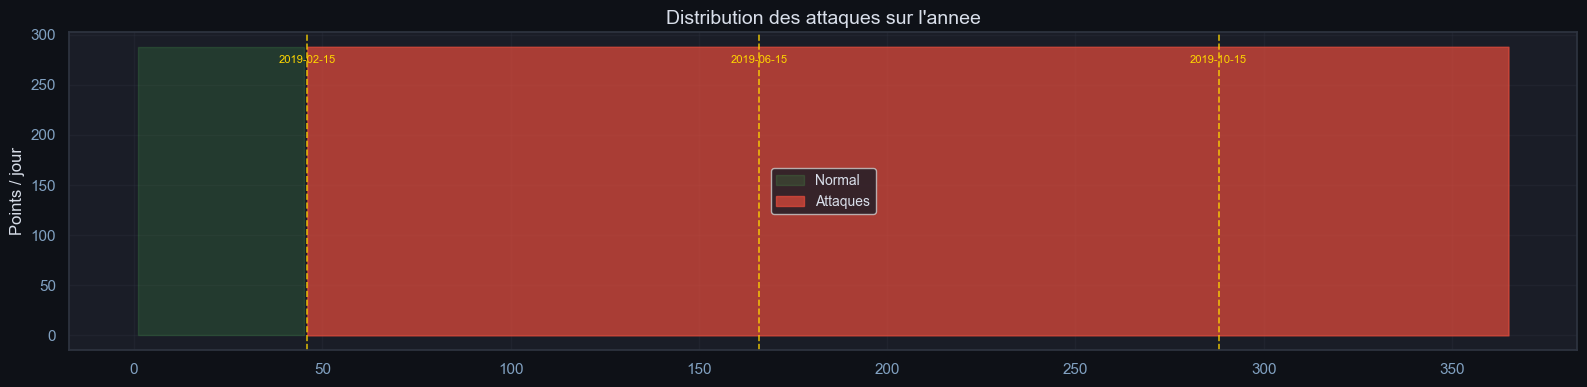

Points normaux: 12,960 | Points attaque: 92,160
Jours avec attaque: 320 / 365


In [6]:
# Since attacks are injected at 3 dates, show the attack timeline
atk_daily = df[df['label']==1].groupby('doy').size()
norm_daily = df[df['label']==0].groupby('doy').size()

fig, ax = plt.subplots(figsize=(16, 4))
ax.fill_between(norm_daily.index, norm_daily.values, alpha=0.2, color='#4CAF50', label='Normal', step='mid')
ax.fill_between(atk_daily.index, atk_daily.values, alpha=0.7, color='#E74C3C', label='Attaques', step='mid')
for d in ['2019-02-15','2019-06-15','2019-10-15']:
    dt = pd.Timestamp(d)
    ax.axvline(dt.dayofyear, color='#FFD700', ls='--', lw=1.2, alpha=0.8)
    ax.text(dt.dayofyear, ax.get_ylim()[1]*0.9, d, fontsize=8, color='#FFD700', ha='center')
ax.set_ylabel('Points / jour'); ax.set_title('Distribution des attaques sur l\'annee', fontsize=14)
ax.legend(fontsize=10); fig.tight_layout(); plt.show()

print(f"Points normaux: {norm_daily.sum():,} | Points attaque: {atk_daily.sum():,}")
print(f"Jours avec attaque: {(atk_daily>0).sum()} / 365")

---
## Resume

| Element | Valeur |
|---|---|
| **Dataset** | 105 120 points, 5 min d'intervalle, 365 jours |
| **Capteurs** | Weather (exterieur), Fridge (frigo), Thermostat (interieur) |
| **Attaques** | 9 types injectes a 3 dates (15 fev, 15 jun, 15 oct) |
| **ML** | Isolation Forest (200 arbres, contamination=0.05) |
| **Performance** | AUC ROC ~0.988, F1-Attaque ~0.996 |

---
*Dashboard interatif genere depuis `generated_yearly_merged.csv`*